               Ad 0          Ad 1          Ad 2          Ad 3          Ad 4  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.170300      0.129500      0.072800      0.119600      0.269500   
std        0.375915      0.335769      0.259821      0.324509      0.443722   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.000000      0.000000      0.000000      0.000000      1.000000   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

               Ad 5          Ad 6          Ad 7          Ad 8         Ad 9  
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.00000  
mean       0.012600      0.111200      0.209100      0.095200      0.04890  
std        0.111546      0.314395      0.406686      0.29

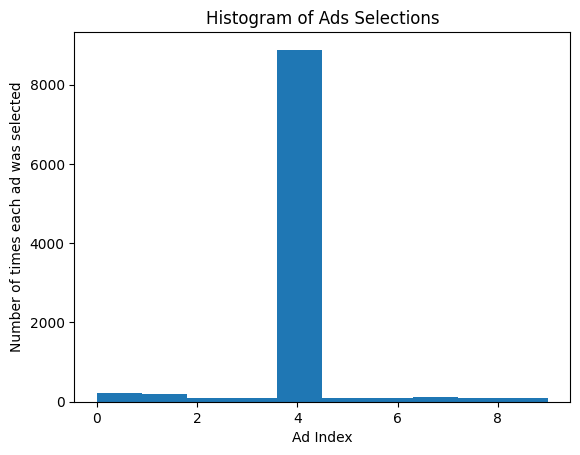

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
dataset = pd.read_csv('Ads_CTR_Optimisation.csv')
print(dataset.describe())

import random
N = 10000 # Total number of users/rounds
d = 10    # Number of ads

# Epsilon-greedy parameter
epsilon = 0.1

# Initialize variables for tracking ad selections and rewards
numbers_of_selections = [0] * d
sums_of_rewards = [0] * d
ads_selected = []
total_reward = 0

# Epsilon-Greedy Algorithm
for n in range(N):
    ad = 0
    # Decide whether to explore or exploit
    if random.uniform(0, 1) < epsilon: # Explore
        ad = random.randrange(d)
    else: # Exploit
        max_upper_bound = 0
        for i in range(d):
            if numbers_of_selections[i] > 0:
                average_reward = sums_of_rewards[i] / numbers_of_selections[i]
                if average_reward > max_upper_bound:
                    max_upper_bound = average_reward
                    ad = i
            else:
                # If an ad hasn't been selected yet, prioritize exploring it
                ad = i
                break

    ads_selected.append(ad)
    numbers_of_selections[ad] += 1
    reward = dataset.values[n, ad] # Get the reward for selecting this ad for this user
    sums_of_rewards[ad] += reward
    total_reward += reward

# Calculate the winning ad
winning_ad_index = np.argmax(sums_of_rewards)

print(f"Total reward: {total_reward}")
print(f"The best ad (index) is: {winning_ad_index}")
print(f"The best ad (number of times selected) is: {numbers_of_selections[winning_ad_index]}")

# Optional: Visualize the histogram of ad selections
plt.hist(ads_selected)
plt.title('Histogram of Ads Selections')
plt.xlabel('Ad Index')
plt.ylabel('Number of times each ad was selected')
plt.show()

In [8]:
import pandas as pd
import numpy as np

data = pd.read_csv('Ads_CTR_Optimisation.csv')

num_users = len(data)
num_ads = len(data.columns)
epsilon = 0.1

ads_selected = []
numbers_of_selections = np.zeros(num_ads)
sums_of_rewards = np.zeros(num_ads)
total_reward = 0

np.random.seed(42)

for user in range(num_users):
    if np.random.rand() < epsilon:
        ad = np.random.randint(0, num_ads)
    else:
        average_rewards = [
            sums_of_rewards[i] / numbers_of_selections[i] if numbers_of_selections[i] > 0 else 0
            for i in range(num_ads)
        ]
        ad = np.argmax(average_rewards)

    reward = data.iloc[user, ad]

    numbers_of_selections[ad] += 1
    sums_of_rewards[ad] += reward
    total_reward += reward

final_averages = [sums_of_rewards[i] / numbers_of_selections[i] if numbers_of_selections[i] > 0 else 0 for i in range(num_ads)]
best_ad_index = np.argmax(final_averages)

print("--- MAB Epsilon-Greedy Simulation Summary ---")
print(f"Total Users Served: {num_users}")
print(f"Total Combined Clicks (Rewards): {total_reward}")
print("\nAd Performance Metrics:")
for i in range(num_ads):
    print(f"Ad {i} -> Times Shown: {int(numbers_of_selections[i])}, Total Clicks: {int(sums_of_rewards[i])}, Estimated CTR: {final_averages[i]:.4f}")

print(f"\nConclusion: The best performing advertisement is **Ad {best_ad_index}** with an estimated Click-Through Rate (CTR) of {final_averages[best_ad_index]:.4f}.")


--- MAB Epsilon-Greedy Simulation Summary ---
Total Users Served: 10000
Total Combined Clicks (Rewards): 2543

Ad Performance Metrics:
Ad 0 -> Times Shown: 297, Total Clicks: 38, Estimated CTR: 0.1279
Ad 1 -> Times Shown: 107, Total Clicks: 11, Estimated CTR: 0.1028
Ad 2 -> Times Shown: 91, Total Clicks: 8, Estimated CTR: 0.0879
Ad 3 -> Times Shown: 100, Total Clicks: 16, Estimated CTR: 0.1600
Ad 4 -> Times Shown: 8870, Total Clicks: 2412, Estimated CTR: 0.2719
Ad 5 -> Times Shown: 108, Total Clicks: 4, Estimated CTR: 0.0370
Ad 6 -> Times Shown: 97, Total Clicks: 13, Estimated CTR: 0.1340
Ad 7 -> Times Shown: 107, Total Clicks: 23, Estimated CTR: 0.2150
Ad 8 -> Times Shown: 111, Total Clicks: 14, Estimated CTR: 0.1261
Ad 9 -> Times Shown: 112, Total Clicks: 4, Estimated CTR: 0.0357

Conclusion: The best performing advertisement is **Ad 4** with an estimated Click-Through Rate (CTR) of 0.2719.


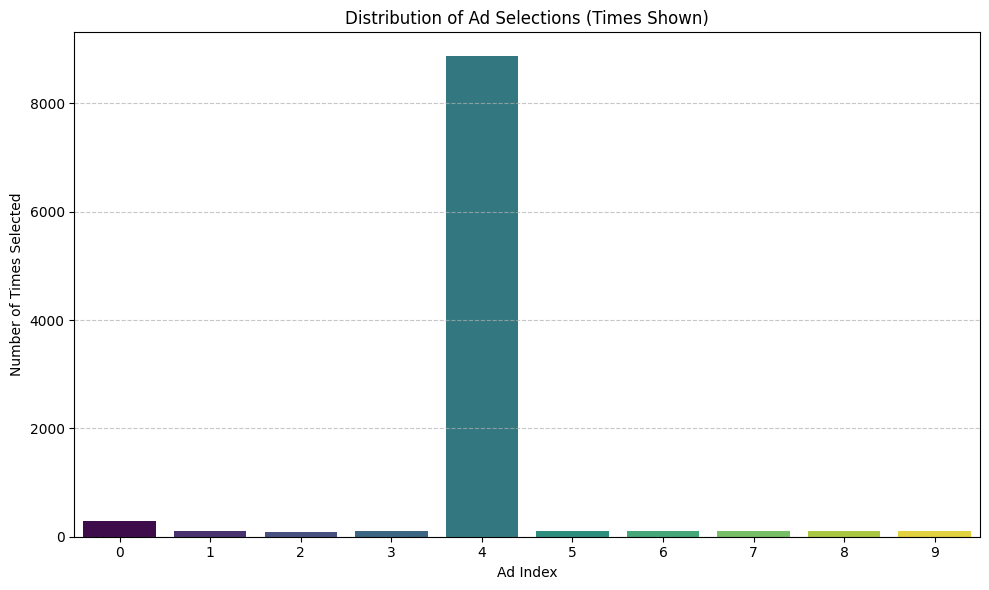

In [10]:
# Histogram of Ad Selections
fig = plt.figure(figsize=(10, 6))
sns.barplot(x=performance_df['Ad Index'], y=performance_df['Times Shown'], hue=performance_df['Ad Index'], palette='viridis', legend=False)
plt.title('Distribution of Ad Selections (Times Shown)')
plt.xlabel('Ad Index')
plt.ylabel('Number of Times Selected')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()